<a href="https://colab.research.google.com/github/vaishnavisachinyadav-ui/ML2/blob/main/ML_Activity2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df_raw = pd.read_csv(url)
df_raw.to_csv("titanic_original.csv", index=False)   # keep the original file

print("Dataset name : Titanic Passenger Dataset")
print("Source link  :", url)
print("File type    : CSV")
print("Rows         :", df_raw.shape[0])
print("Columns      :", df_raw.shape[1])

Dataset name : Titanic Passenger Dataset
Source link  : https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv
File type    : CSV
Rows         : 891
Columns      : 15


In [3]:
df_raw.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
df_raw.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [5]:
print("Rows   :", df_raw.shape[0])
print("Columns:", df_raw.shape[1])
print("\nColumn names:", list(df_raw.columns))
print("\nData types:")
print(df_raw.dtypes)

Rows   : 891
Columns: 15

Column names: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Data types:
survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object


In [6]:
numerical_cols = df_raw.select_dtypes(include='number').columns.tolist()
categorical_cols = df_raw.select_dtypes(exclude='number').columns.tolist()

print("Numerical columns  :", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns  : ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']
Categorical columns: ['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [7]:
df_raw[numerical_cols].describe().round(2)

,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,714.00,891.00,891.00,891.00
mean,0.38,2.31,29.70,0.52,0.38,32.20
std,0.49,0.84,14.53,1.10,0.81,49.69
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,2.00,20.12,0.00,0.00,7.91
50%,0.00,3.00,28.00,0.00,0.00,14.45
75%,1.00,3.00,38.00,1.00,0.00,31.00
max,1.00,3.00,80.00,8.00,6.00,512.33


In [8]:
print("Passengers with fare = 0 :", (df_raw['fare'] == 0).sum())
print("Highest fare             :", df_raw['fare'].max())
print("Age range                : %.2f to %.2f" % (df_raw['age'].min(), df_raw['age'].max()))
print("Children below age 1     :", (df_raw['age'] < 1).sum())

print("\nCheck: class vs pclass")
print(pd.crosstab(df_raw['class'], df_raw['pclass']))
print("\nCheck: alive vs survived")
print(pd.crosstab(df_raw['alive'], df_raw['survived']))

Passengers with fare = 0 : 15
Highest fare             : 512.3292
Age range                : 0.42 to 80.00
Children below age 1     : 7

Check: class vs pclass
pclass    1    2    3
class                
First   216    0    0
Second    0  184    0
Third     0    0  491

Check: alive vs survived
survived    0    1
alive             
no        549    0
yes         0  342


In [9]:
missing_count = df_raw.isnull().sum()
missing_percent = (missing_count / len(df_raw) * 100).round(2)

missing_table = pd.DataFrame({'Missing Count': missing_count, 'Missing %': missing_percent})
missing_table.sort_values('Missing Count', ascending=False)

,Missing Count,Missing %
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22
sex,0,0.00
pclass,0,0.00
survived,0,0.00
fare,0,0.00
parch,0,0.00
sibsp,0,0.00


In [10]:
print("Columns with NO missing values:")
print(missing_table[missing_table['Missing Count'] == 0].index.tolist())

print("\nColumns that need attention:")
print(missing_table[missing_table['Missing Count'] > 0].index.tolist())

Columns with NO missing values:
['survived', 'pclass', 'sex', 'sibsp', 'parch', 'fare', 'class', 'who', 'adult_male', 'alive', 'alone']

Columns that need attention:
['age', 'embarked', 'deck', 'embark_town']


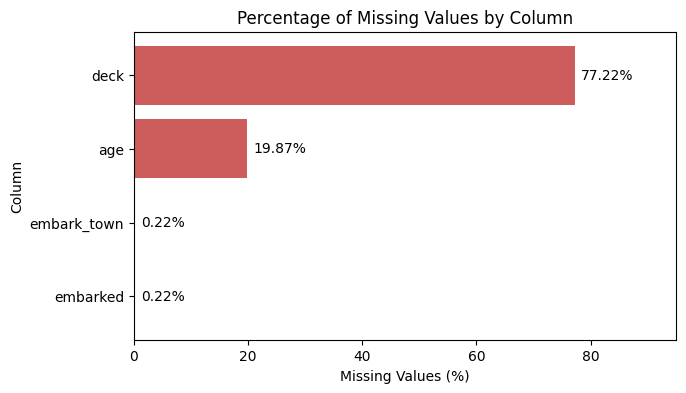

In [11]:
cols_missing = missing_table[missing_table['Missing Count'] > 0]['Missing %'].sort_values()

plt.figure(figsize=(7, 4))
plt.barh(cols_missing.index, cols_missing.values, color='indianred')
plt.title("Percentage of Missing Values by Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
for i, v in enumerate(cols_missing.values):
    plt.text(v + 1, i, f"{v}%", va='center')
plt.xlim(0, 95)
plt.show()

In [12]:
df = df_raw.copy()      # work on a copy

# 1. Drop 'deck' (77% missing, too much to fill reliably)
df = df.drop(columns=['deck'])

# 2. Fill 'age' with the median
age_median = df['age'].median()
df['age'] = df['age'].fillna(age_median)
print("Median age used:", age_median)

# 3. Fill categorical columns with the mode
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])
print("Mode for embarked   :", df['embarked'].mode()[0])
print("Mode for embark_town:", df['embark_town'].mode()[0])

Median age used: 28.0
Mode for embarked   : S
Mode for embark_town: Southampton


In [13]:
print("Missing values after handling:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

Missing values after handling:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

Total missing values: 0


In [14]:
print("Duplicate rows in the ORIGINAL data      :", df_raw.duplicated().sum())
print("Duplicate rows after filling missing ages:", df.duplicated().sum())

dups = df[df.duplicated(keep=False)].sort_values(list(df.columns))
dups.head(10)

Duplicate rows in the ORIGINAL data      : 107
Duplicate rows after filling missing ages: 116


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
633,0,1,male,28.0,0,0,0.0000,S,First,man,True,Southampton,no,True
815,0,1,male,28.0,0,0,0.0000,S,First,man,True,Southampton,no,True
64,0,1,male,28.0,0,0,27.7208,C,First,man,True,Cherbourg,no,True
295,0,1,male,28.0,0,0,27.7208,C,First,man,True,Cherbourg,no,True
252,0,1,male,62.0,0,0,26.5500,S,First,man,True,Southampton,no,True
555,0,1,male,62.0,0,0,26.5500,S,First,man,True,Southampton,no,True
144,0,2,male,18.0,0,0,11.5000,S,Second,man,True,Southampton,no,True
757,0,2,male,18.0,0,0,11.5000,S,Second,man,True,Southampton,no,True
658,0,2,male,23.0,0,0,13.0000,S,Second,man,True,Southampton,no,True
733,0,2,male,23.0,0,0,13.0000,S,Second,man,True,Southampton,no,True


In [15]:
print("Duplicate rows by ticket class and sex:")
print(dups.groupby(['pclass', 'sex']).size())

Duplicate rows by ticket class and sex:
pclass  sex   
1       female      2
        male       10
2       female      8
        male       25
3       female     25
        male      104
dtype: int64


In [16]:
REMOVE_DUPLICATES = False      # set True if you want to remove them

if REMOVE_DUPLICATES:
    df = df.drop_duplicates()

print("Rows now:", len(df))

Rows now: 891


In [17]:
text_cols = df.select_dtypes(exclude=['number', 'bool']).columns.tolist()

for col in text_cols:
    df[col] = df[col].astype(str).str.strip()

df['sex'] = df['sex'].str.lower()
df['who'] = df['who'].str.lower()
df['embarked'] = df['embarked'].str.upper()

for col in text_cols:
    print(col, "->", sorted(df[col].unique()))

sex -> ['female', 'male']
embarked -> ['C', 'Q', 'S']
class -> ['First', 'Second', 'Third']
who -> ['child', 'man', 'woman']
embark_town -> ['Cherbourg', 'Queenstown', 'Southampton']
alive -> ['no', 'yes']


In [18]:
# Remove columns that repeat information
df = df.drop(columns=['class', 'alive', 'embark_town'])

# Convert True/False to 1/0
df['adult_male'] = df['adult_male'].astype(int)
df['alone'] = df['alone'].astype(int)

print("Columns now:", list(df.columns))
print("Shape      :", df.shape)

Columns now: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'who', 'adult_male', 'alone']
Shape      : (891, 11)


In [19]:
df[['age', 'sibsp', 'parch', 'fare']].describe().round(2)

,age,sibsp,parch,fare
count,891.00,891.00,891.00,891.00
mean,29.36,0.52,0.38,32.20
std,13.02,1.10,0.81,49.69
min,0.42,0.00,0.00,0.00
25%,22.00,0.00,0.00,7.91
50%,28.00,0.00,0.00,14.45
75%,35.00,1.00,0.00,31.00
max,80.00,8.00,6.00,512.33


In [20]:
print("Passengers by sex:")
print(df['sex'].value_counts())
print("\nPassengers by port of boarding:")
print(df['embarked'].value_counts())
print("\nPassengers by ticket class:")
print(df['pclass'].value_counts().sort_index())

Passengers by sex:
sex
male      577
female    314
Name: count, dtype: int64

Passengers by port of boarding:
embarked
S    646
C    168
Q     77
Name: count, dtype: int64

Passengers by ticket class:
pclass
1    216
2    184
3    491
Name: count, dtype: int64


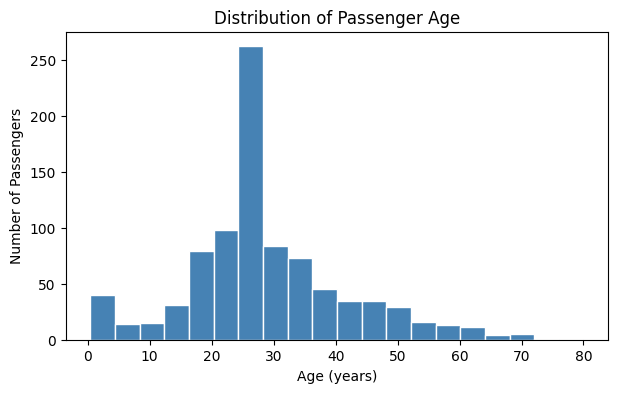

In [21]:
# Graph 1: Histogram of age
plt.figure(figsize=(7, 4))
plt.hist(df['age'], bins=20, color='steelblue', edgecolor='white')
plt.title("Distribution of Passenger Age")
plt.xlabel("Age (years)")
plt.ylabel("Number of Passengers")
plt.show()

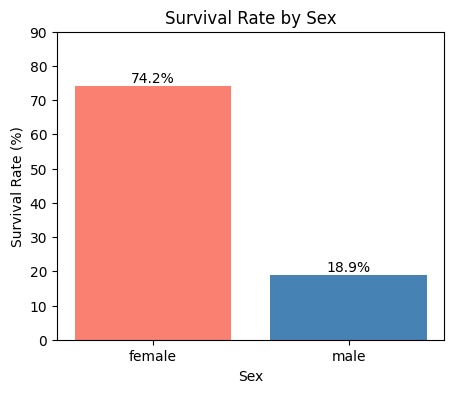

In [22]:
# Graph 2: Survival rate by sex
survival_by_sex = df.groupby('sex')['survived'].mean() * 100

plt.figure(figsize=(5, 4))
plt.bar(survival_by_sex.index, survival_by_sex.values, color=['salmon', 'steelblue'])
plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Rate (%)")
for i, v in enumerate(survival_by_sex.values):
    plt.text(i, v + 1, f"{v:.1f}%", ha='center')
plt.ylim(0, 90)
plt.show()

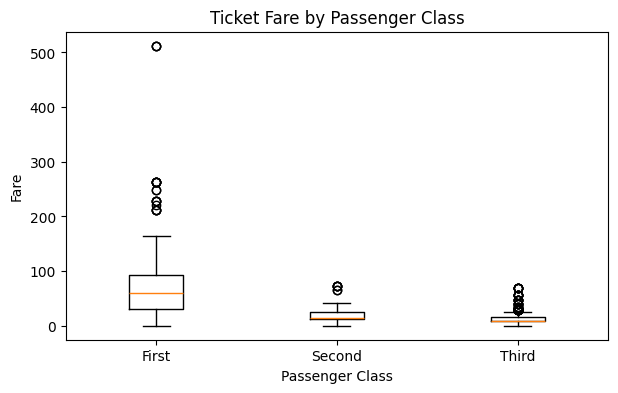

In [23]:
# Graph 3: Box plot of fare by class
fare_data = [df[df['pclass'] == c]['fare'] for c in [1, 2, 3]]

plt.figure(figsize=(7, 4))
plt.boxplot(fare_data, tick_labels=['First', 'Second', 'Third'])
plt.title("Ticket Fare by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Fare")
plt.show()

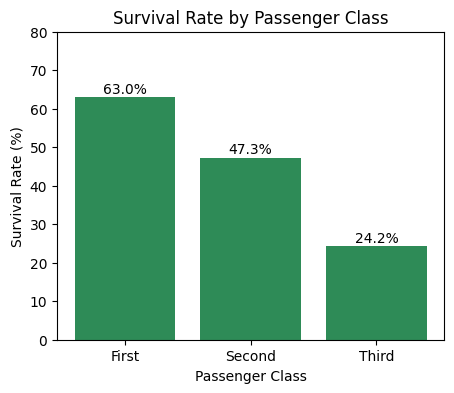

In [24]:
# Graph 4: Survival rate by class
survival_by_class = df.groupby('pclass')['survived'].mean() * 100

plt.figure(figsize=(5, 4))
plt.bar(['First', 'Second', 'Third'], survival_by_class.values, color='seagreen')
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
for i, v in enumerate(survival_by_class.values):
    plt.text(i, v + 1, f"{v:.1f}%", ha='center')
plt.ylim(0, 80)
plt.show()

In [25]:
cat_cols = ['sex', 'embarked', 'who']

print("BEFORE encoding (sample):")
print(df[cat_cols].head())
print("\nColumns before:", df.shape[1])

BEFORE encoding (sample):
      sex embarked    who
0    male        S    man
1  female        C  woman
2  female        S  woman
3  female        S  woman
4    male        S    man

Columns before: 11


In [26]:
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

new_cols = [c for c in df_encoded.columns if c.startswith(('sex_', 'embarked_', 'who_'))]
print("AFTER encoding (sample of new columns):")
print(df_encoded[new_cols].head())
print("\nNew columns created:", new_cols)
print("Columns after:", df_encoded.shape[1])

AFTER encoding (sample of new columns):
   sex_male  embarked_Q  embarked_S  who_man  who_woman
0         1           0           1        1          0
1         0           0           0        0          1
2         0           0           1        0          1
3         0           0           1        0          1
4         1           0           1        1          0

New columns created: ['sex_male', 'embarked_Q', 'embarked_S', 'who_man', 'who_woman']
Columns after: 13


In [27]:
scale_cols = ['age', 'sibsp', 'parch', 'fare']

print("Range BEFORE scaling:")
print(df_encoded[scale_cols].agg(['min', 'max', 'mean', 'std']).round(2))

Range BEFORE scaling:
        age  sibsp  parch    fare
min    0.42   0.00   0.00    0.00
max   80.00   8.00   6.00  512.33
mean  29.36   0.52   0.38   32.20
std   13.02   1.10   0.81   49.69


In [28]:
# Learn scaling values from TRAINING rows only
train_idx, test_idx = train_test_split(df_encoded.index, test_size=0.2, random_state=42)

scaler = StandardScaler()
scaler.fit(df_encoded.loc[train_idx, scale_cols])

df_final = df_encoded.copy()
df_final[scale_cols] = scaler.transform(df_encoded[scale_cols])

print("Mean/Std learned from training data:")
print(pd.DataFrame({'mean': scaler.mean_, 'std': scaler.scale_}, index=scale_cols).round(3))

print("\nStats AFTER scaling (training rows):")
print(df_final.loc[train_idx, scale_cols].agg(['mean', 'std']).round(3))

Mean/Std learned from training data:
         mean     std
age    29.204  12.999
sibsp   0.553   1.176
parch   0.379   0.791
fare   32.586  51.933

Stats AFTER scaling (training rows):
        age  sibsp  parch   fare
mean  0.000  0.000  0.000  0.000
std   1.001  1.001  1.001  1.001


In [29]:
print("Final shape:", df_final.shape)
print("Remaining missing values:", df_final.isnull().sum().sum())
print("Duplicate rows (genuine passengers, kept):", df_final.duplicated().sum())
print("\nFinal columns:", list(df_final.columns))

Final shape: (891, 13)
Remaining missing values: 0
Duplicate rows (genuine passengers, kept): 116

Final columns: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'adult_male', 'alone', 'sex_male', 'embarked_Q', 'embarked_S', 'who_man', 'who_woman']


In [30]:
df.to_csv("titanic_cleaned.csv", index=False)
df_final.to_csv("titanic_prepared.csv", index=False)

print("Saved files:")
print(" - titanic_original.csv")
print(" - titanic_cleaned.csv")
print(" - titanic_prepared.csv")

Saved files:
 - titanic_original.csv
 - titanic_cleaned.csv
 - titanic_prepared.csv


In [31]:
pd.read_csv("titanic_prepared.csv").head()

,survived,pclass,age,sibsp,parch,fare,adult_male,alone,sex_male,embarked_Q,embarked_S,who_man,who_woman
0,0,3,-0.554214,0.379923,-0.479342,-0.487864,1,0,1,0,1,1,0
1,1,1,0.676666,0.379923,-0.479342,0.745133,0,0,0,0,0,0,1
2,1,3,-0.246494,-0.470722,-0.479342,-0.474867,0,1,0,0,1,0,1
3,1,1,0.445876,0.379923,-0.479342,0.395003,0,0,0,0,1,0,1
4,0,3,0.445876,-0.470722,-0.479342,-0.472460,1,1,1,0,1,1,0


In [32]:
from google.colab import files
files.download("titanic_prepared.csv")
files.download("titanic_cleaned.csv")
files.download("titanic_original.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>